(sec-2)=
# 2. Datos: ETL y EDA

El ETL, la auditoría de calidad, el EDA completo y el preprocesamiento son los del tercer entregable (secciones 1 a 3 de su cuaderno) y no cambian: se eliminan los duplicados exactos, se reconstruye el calendario a partir del orden del archivo (año, mes y día de contacto), se excluye `duration` por fuga, se retiran `euribor3m` y `emp.var.rate` por multicolinealidad, `pdays = 999` se trata como faltante con indicador y las categóricas se codifican con *one-hot*. Esta sección resume la partición heredada y agrega el único análisis nuevo, que es el que motiva el modelo original.

(sec-2-1)=
## 2.1 Partición y protocolo heredados

In [7]:
n_dias_tr, n_dias_te = len(np.unique(dia_tr)), len(np.unique(dia_te))
resumen_part = pd.DataFrame({
    "Registros": [len(X_tr), len(X_te)], "Desde": [periodo_tr.iloc[0], periodo_te.iloc[0]],
    "Hasta": [periodo_tr.iloc[-1], periodo_te.iloc[-1]], "Días de contacto": [n_dias_tr, n_dias_te],
    "Positivos": [int(y_tr.sum()), int(y_te.sum())], "Prevalencia": [y_tr.mean(), y_te.mean()]},
    index=["Entrenamiento (primer 80 %)", "Prueba (último 20 %)"])
tabla(resumen_part, dec=3)
print(f"Validación anidada: TimeSeriesSplit de {cfg.K_EXTERNO} pliegues externos y {cfg.K_INTERNO} internos, "
      f"separación de {GAP} registros (un día de contactos), {cfg.PRESUPUESTO} configuraciones por optimizador.")

,Registros,Desde,Hasta,Días de contacto,Positivos,Prevalencia
Entrenamiento (primer 80 %),32 940,2008-05,2009-05,166,2 100,"0,064"
Prueba (último 20 %),8 236,2009-05,2010-11,323,2 539,"0,308"


Validación anidada: TimeSeriesSplit de 5 pliegues externos y 3 internos, separación de 507 registros (un día de contactos), 20 configuraciones por optimizador.


(sec-2-2)=
## 2.2 Nuevo hallazgo: la tasa diaria de suscripción es un nivel latente persistente

Si la información que falta está en el momento de la llamada (sección {ref}`1.1 <sec-1-1>`), debe aparecer como **dependencia temporal en la tasa de suscripción de cada día**. Se calcula, solo con el entrenamiento, el logit empírico diario $\ell_t = \log\{(s_t + 0{,}5)/(n_t - s_t + 0{,}5)\}$, donde $s_t$ son las suscripciones y $n_t$ las llamadas del día $t$, y su autocorrelación. Luego se construye un puntaje que **no usa ninguna variable del cliente**: la tasa de los días ya cerrados, promediada con un suavizado exponencial, y se evalúa en los mismos cinco pliegues externos de los benchmarks.

,Pliegue 1,Pliegue 2,Pliegue 3,Pliegue 4,Pliegue 5,Media
Puntaje,,,,,,
"Solo nivel, semivida de 1 día","0,040","0,067","0,063","0,103","0,241","0,103"
"Solo nivel, semivida de 3 días","0,039","0,066","0,059","0,060","0,202","0,085"
"Solo nivel, semivida de 10 días","0,039","0,066","0,054","0,051","0,125","0,067"
Mejor benchmark: Naive Bayes · class_weight · Bayesiana (Optuna TPE),"0,044","0,060","0,062","0,052","0,296","0,103"


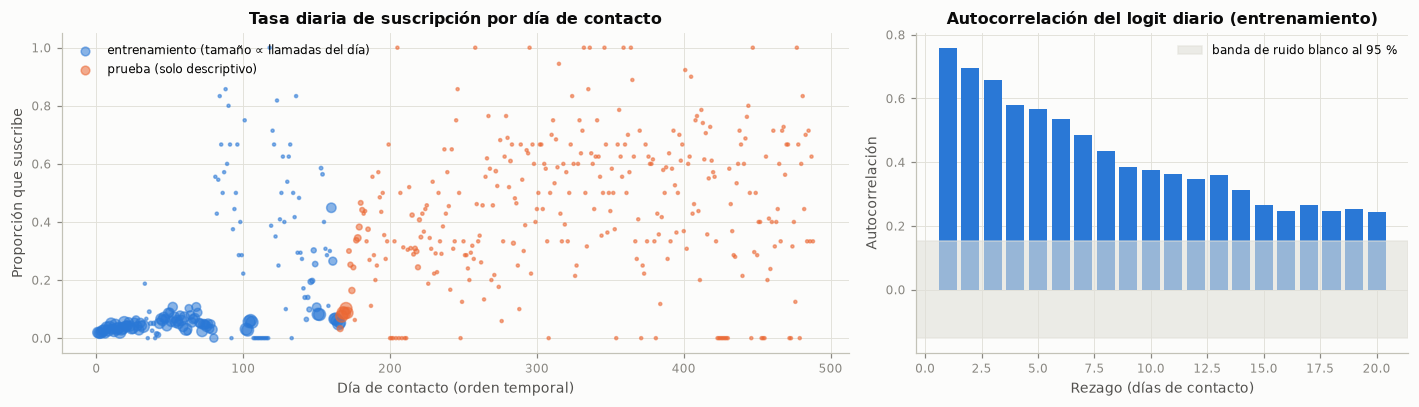

**Interpretación.** En los 166 días de contacto del entrenamiento, la autocorrelación del logit diario es de 0,76 al primer rezago y todavía de 0,57 al quinto y de 0,38 al décimo, muy por encima de la banda de ruido blanco (±0,15). Un puntaje que solo conoce la tasa de los días cerrados, sin ninguna variable del cliente, alcanza un AUC-PR externo medio de 0,103 (semivida de 1 día), frente a 0,103 de la mejor de las 140 combinaciones. Con el nivel suavizado del modelo ajustado al entrenamiento, la proporción de la varianza latente que corresponde al día es de 27,8 %.

Esto quiere decir que la tasa de conversión no es una constante del periodo con ruido alrededor: es un proceso que se mueve con memoria larga, de modo que el día de ayer informa sobre el de hoy. Esa sola estructura, que ningún benchmark modela, vale casi tanto como todo lo que los 140 modelos aprendieron de las variables del cliente; por eso los modelos estáticos se empatan entre sí y por eso la recalibración mensual funcionó. Hay que tener en cuenta que el hallazgo describe asociación temporal, no causa: el nivel resume el contexto de cada día (la lista de clientes llamada, la campaña, la economía), que no está en los datos.

En consecuencia, se decide construir un modelo con dos componentes que se combinan en el logit: un nivel diario latente, que se estima de forma conjunta en el entrenamiento y se actualiza con las etiquetas de los días cerrados, y el efecto de las variables del cliente, que es el que ordena a los clientes de un mismo día. Toda la evidencia de esta sección proviene del entrenamiento y del bucle externo; la prueba se usa una sola vez en la sección 6.

In [8]:
from statsmodels.tsa.stattools import acf

d_tr = pd.DataFrame({"dia": dia_tr, "y": y_tr.to_numpy(), "periodo": periodo_tr.to_numpy()})
g_tr = d_tr.groupby("dia").agg(n=("y", "size"), s=("y", "sum"), periodo=("periodo", "first"))
g_tr["logit"] = np.log((g_tr["s"] + 0.5) / (g_tr["n"] - g_tr["s"] + 0.5))
fac = acf(g_tr["logit"], nlags=20, fft=False)
banda = 1.96 / np.sqrt(len(g_tr))


def puntaje_nivel(semivida):
    """Tasa suavizada de los días anteriores (sin información del cliente), por registro de entrenamiento."""
    a = 1 - 0.5 ** (1 / semivida)
    tasa = (g_tr["s"].ewm(alpha=a).mean() / g_tr["n"].ewm(alpha=a).mean()).shift(1)
    return tasa.reindex(dia_tr).fillna(y_tr.mean()).to_numpy()


filas = []
for sv in (1, 3, 10):
    s_ = puntaje_nivel(sv)
    for k_, (i_e, i_v) in enumerate(cv_externa(GAP).split(X_tr)):
        filas.append({"Puntaje": f"Solo nivel, semivida de {sv} día{'s' if sv > 1 else ''}", "pliegue": k_,
                      "auc_pr": average_precision_score(y_tr.iloc[i_v], s_[i_v])})
solo_nivel = pd.DataFrame(filas).pivot_table(index="Puntaje", columns="pliegue", values="auc_pr", sort=False)
solo_nivel.loc[f"Mejor benchmark: {NOMBRE[MEJOR]}"] = ap_fold[MEJOR].to_numpy()
solo_nivel.columns = [f"Pliegue {c + 1}" for c in range(cfg.K_EXTERNO)]
solo_nivel["Media"] = solo_nivel.mean(axis=1)
tabla(solo_nivel, dec=3)

# Proporción de la variabilidad latente que es diaria, con el nivel suavizado del L2E ajustado al entrenamiento
nivel_tr = L2E["pipeline"][-1].nivel_
icc = np.var(nivel_tr) / (np.var(nivel_tr) + np.pi ** 2 / 3)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
d_te = pd.DataFrame({"dia": dia_te, "y": yte}).groupby("dia")["y"].agg(["size", "mean"])
axs[0].scatter(g_tr.index, g_tr["s"] / g_tr["n"], s=np.clip(g_tr["n"] / 8, 4, 60), color=AZUL, alpha=0.55,
               label="entrenamiento (tamaño ∝ llamadas del día)")
axs[0].scatter(d_te.index, d_te["mean"], s=np.clip(d_te["size"] / 8, 4, 60), color=NARANJA, alpha=0.55, label="prueba (solo descriptivo)")
axs[0].set(title="Tasa diaria de suscripción por día de contacto", xlabel="Día de contacto (orden temporal)",
           ylabel="Proporción que suscribe")
axs[0].legend(loc="upper left")
axs[1].bar(range(1, 21), fac[1:], color=AZUL)
axs[1].axhspan(-banda, banda, color=REJILLA, alpha=0.6, label="banda de ruido blanco al 95 %")
axs[1].set(title="Autocorrelación del logit diario (entrenamiento)", xlabel="Rezago (días de contacto)",
           ylabel="Autocorrelación")
axs[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

mejor_nivel = solo_nivel.iloc[:3]["Media"].idxmax()
para_guion("solo_nivel", solo_nivel.reset_index())
para_guion("eda", {"dias_tr": len(g_tr), "acf1": fac[1], "acf5": fac[5], "acf10": fac[10], "banda": banda, "icc": icc,
                   "solo_nivel": solo_nivel.loc[mejor_nivel, "Media"], "mejor_140": solo_nivel.iloc[-1]["Media"],
                   "n_tr": len(X_tr), "n_te": len(X_te), "prev_tr": y_tr.mean(), "prev_te": y_te.mean(),
                   "desde_tr": periodo_tr.iloc[0], "hasta_tr": periodo_tr.iloc[-1], "desde_te": periodo_te.iloc[0],
                   "hasta_te": periodo_te.iloc[-1], "dias_te": n_dias_te, "gap": GAP})
interpretar(
    f"En los {len(g_tr)} días de contacto del entrenamiento, la autocorrelación del logit diario es de "
    f"{num(fac[1], 2)} al primer rezago y todavía de {num(fac[5], 2)} al quinto y de {num(fac[10], 2)} al décimo, "
    f"muy por encima de la banda de ruido blanco (±{num(banda, 2)}). Un puntaje que solo conoce la tasa de los días "
    f"cerrados, sin ninguna variable del cliente, alcanza un AUC-PR externo medio de "
    f"{num(solo_nivel.loc[mejor_nivel, 'Media'], 3)} ({mejor_nivel.split(', ')[1]}), frente a "
    f"{num(solo_nivel.iloc[-1]['Media'], 3)} de la mejor de las 140 combinaciones. Con el nivel suavizado del modelo "
    f"ajustado al entrenamiento, la proporción de la varianza latente que corresponde al día es de {pct(icc)}.",
    conectar("Esto quiere decir que", "La tasa de conversión no es una constante del periodo con ruido alrededor: es un "
             "proceso que se mueve con memoria larga, de modo que el día de ayer informa sobre el de hoy. Esa sola "
             "estructura, que ningún benchmark modela, vale casi tanto como todo lo que los 140 modelos aprendieron de "
             "las variables del cliente; por eso los modelos estáticos se empatan entre sí y por eso la recalibración "
             "mensual funcionó. Hay que tener en cuenta que el hallazgo describe asociación temporal, no causa: el nivel "
             "resume el contexto de cada día (la lista de clientes llamada, la campaña, la economía), que no está en "
             "los datos."),
    conectar("En consecuencia, se decide", "Construir un modelo con dos componentes que se combinan en el logit: un "
             "nivel diario latente, que se estima de forma conjunta en el entrenamiento y se actualiza con las "
             "etiquetas de los días cerrados, y el efecto de las variables del cliente, que es el que ordena a los "
             "clientes de un mismo día. Toda la evidencia de esta sección proviene del entrenamiento y del bucle "
             "externo; la prueba se usa una sola vez en la sección 6."))